## Pytorch 

Dans ce dernier tutoriel de la première partie du cours, nous allons nous intéresser à Pytorch, une librairie qui permet de coder des réseaux de neurones. 

Pytorch est très similaire à numpy dans le sens où les deux librairies permettent de faire des opérations sur des données tabulées. 

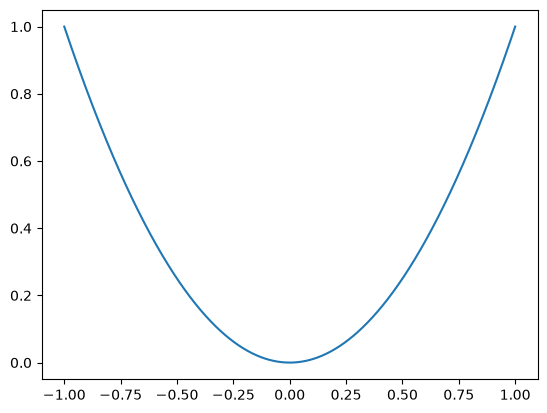

In [2]:
import torch 
import matplotlib.pyplot as plt 

x = torch.linspace(-1, 1, 1000)
y = x ** 2

plt.plot(x, y)

L'équivalent de `np.array` est `torch.tensor` comme on voit ci-dessous

In [9]:
x = torch.tensor([1, 2, 3, 4])
print(x)

tensor([1, 2, 3, 4])


On peut aussi faire des opérations de base...

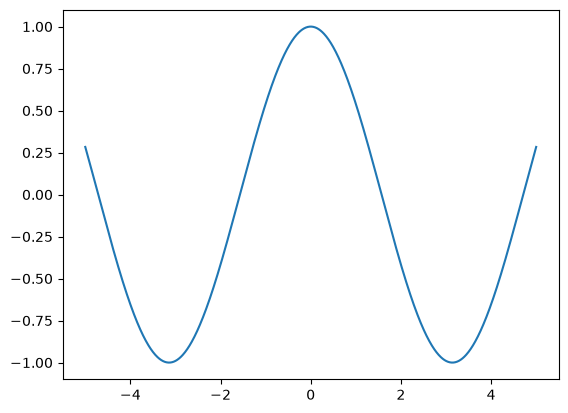

In [11]:
x = torch.linspace(-5, 5, 1000)
y = torch.cos(x)
plt.plot(x, y)

In [14]:
x = torch.tensor([10, 18, 20, 19, 17], dtype=torch.float32)
print("Moyenne", x.mean())
print("Déviation standard", x.std())
print("Somme", x.sum())

Moyenne tensor(16.8000)
Déviation standard tensor(3.9623)
Somme tensor(84.)


L'avantage par rapport à numpy est qu'on va pouvoir mettre faire des opérations sur GPU. 
On peut changer l'environnement d'exécution sur google colab pour avoir accès à un GPU. 

In [8]:
device = "cuda" if torch.cuda.is_available() else "cpu"

print(device)
x = torch.tensor([1, 2]).to(device)

cpu


## Nombres aléatoires 

Pytorch a aussi ses propres fonctions pour créer des nombres aléatoires  

(array([0.51060598, 0.46555251, 0.51060598, 0.47556439, 0.53563585,
        0.51060583, 0.50059395, 0.52061802, 0.51060613, 0.46555237]),
 array([1.70898438e-03, 2.01471627e-01, 4.01234269e-01, 6.00996912e-01,
        8.00759554e-01, 1.00052214e+00, 1.20028484e+00, 1.40004754e+00,
        1.59981012e+00, 1.79957271e+00, 1.99933541e+00]),
 <BarContainer object of 10 artists>)

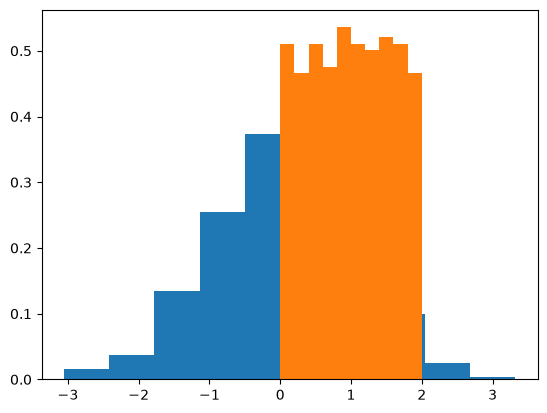

In [ ]:
z = torch.randn((1000,))      # Gaussian distribution
z_2 = 2 * torch.rand((1000,)) # uniform distribution
plt.hist(z, density = True)
plt.hist(z_2, density = True)

### Différentiation automatique

On va pouvoir également calculer les dérivées de fonction assez simplement avec pytorch

In [20]:
from torch.func import grad, vmap
def square(x):
    return x ** 2

x = torch.linspace(-5, 5, 1000)
y_prime = vmap(grad(square))(x)

[Text(0.5, 0, '$x$')]

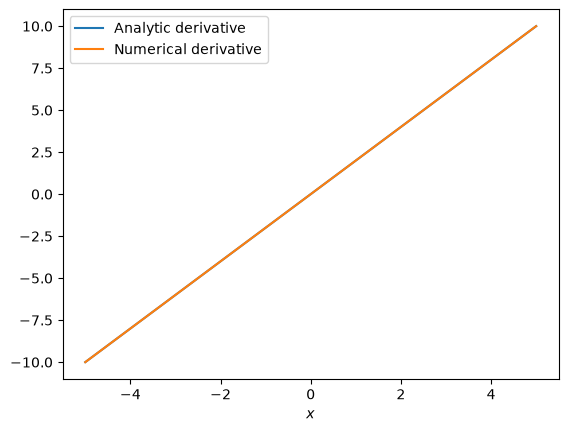

In [24]:
plt.plot(x, 2 * x, label = "Analytic derivative")
plt.plot(x, y_prime, label = "Numerical derivative")
plt.legend()
plt.gca().set(xlabel = r"$x$")

### Réseaux de neurones avec Pytorch

De manière plus importante, Pytorch va nous permettre de créer des réseaux de neurones. Comme on verra dans le cours, on peut voir un réseau de neurone comme un approximateur de fonctions. On va ici essayer d'apprendre la fonction $x^3$ avec Pytorch. 

In [29]:
from torch import nn
class MLP(nn.Module):
    def __init__(self, input_dim = 1, hidden_dim = 32, output_dim = 1):
        super(MLP, self).__init__()

        # Adding input dim and output dim to list of widths
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.SiLU(inplace = True),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(inplace = True),
            nn.Linear(hidden_dim, output_dim)
        )

    def forward(self, x):
        return self.net(x)

x = torch.rand((10, 1))
net = MLP()
net(x) 

tensor([[ 0.0038],
        [ 0.0164],
        [ 0.0046],
        [ 0.0122],
        [-0.0046],
        [ 0.0153],
        [-0.0150],
        [-0.0041],
        [-0.0157],
        [-0.0060]], grad_fn=<AddmmBackward0>)

##### Visualisation des données sur lesquelles on entraine

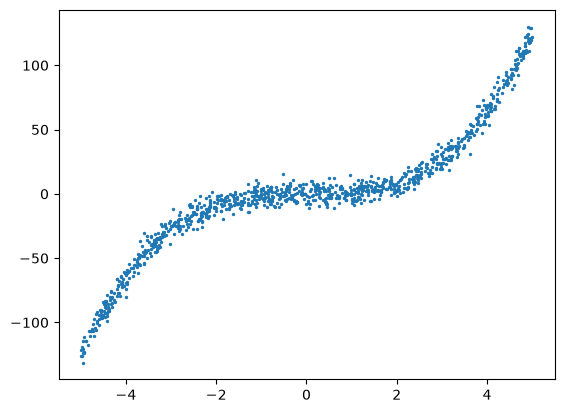

In [40]:
def simulate_data(num_samples = 1000, sigma = 5):
    x = 10 * torch.rand((1000,1)) - 5 
    y =  x ** 3 + sigma * torch.randn_like(x) # adding noise

    return x, y

plt.scatter(*simulate_data(1000), s = 2)

In [54]:
from tqdm import tqdm 
from torch.optim import Adam


net = MLP().to(device)
optimizer = Adam(params = net.parameters(), lr = 1e-3)
loss_fn = nn.MSELoss()

epochs = 10000
batch_size = 10000
losses = []
for epoch in tqdm(range(epochs)): 

    # Zero-ing the gradients
    optimizer.zero_grad()
    x, y = simulate_data(batch_size)
    y_pred = net(x)

    # Computing the loss 
    loss = loss_fn(y, y_pred)

    # Computing the derivative of the loss w.r.t. net parameters 
    loss.backward()

    # Optimizer step
    optimizer.step()

    losses.append(loss.detach().cpu())

100%|██████████| 10000/10000 [00:11<00:00, 905.05it/s]


On peut visualiser la fonction d'erreur en fonction du nombre d'epochs

[Text(0.5, 0, 'Epochs'), Text(0, 0.5, 'Loss')]

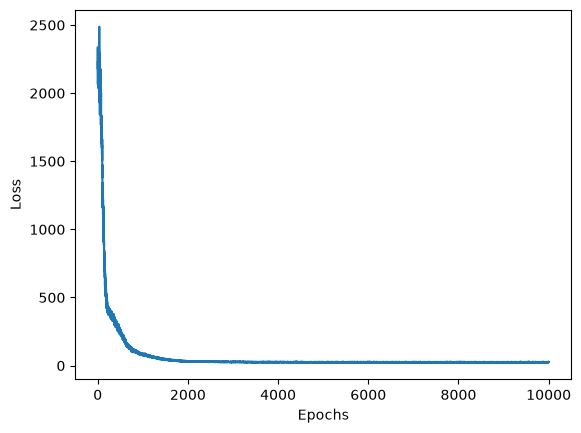

In [55]:
plt.plot(losses)
plt.gca().set(xlabel = r"Epochs", ylabel = "Loss")

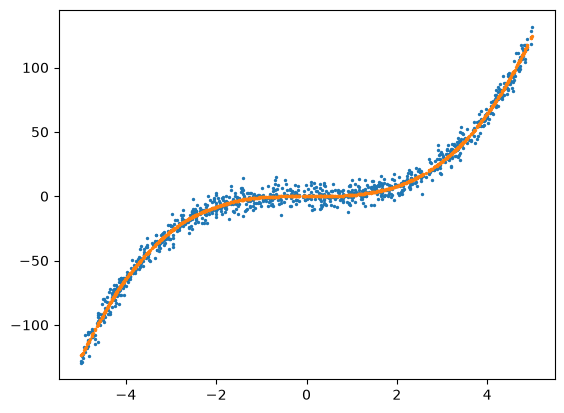

In [56]:
x, y = simulate_data()
y_pred = net(x).detach()
plt.scatter(x, y, s = 2)
plt.scatter(x, y_pred, s= 2)

Et voilà ceci est votre premier réseau de neurones !!